# Practical Application III: Comparing Classifiers
### Predicting Term-Deposit Subscription in a Portuguese Bank's Telemarketing Campaigns

**Data:** UCI *Bank Marketing (with social/economic context)* — `bank-additional-full.csv` (Moro, Cortez & Rita, 2014)  
**Methodology:** CRISP-DM (Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment recommendations)  
**Models compared:** Logistic Regression, K-Nearest Neighbors, Decision Tree, Support Vector Machine

---
**Executive summary** (details and evidence follow below)

* **Business problem:** Reduce wasted telemarketing effort by predicting *before the call* which customers will subscribe to a term deposit, so agents call the likeliest buyers first.
* **Data:** 41,188 contacts, 17 campaigns (2008–2010). Only **11.3%** subscribed (heavily imbalanced).
* **Key result 1 – accuracy is misleading.** Always predicting "no" scores **88.7%**. A logistic regression on bank-profile features alone *also* scores 88.7% — it never predicts a single subscriber (recall 0%, ROC-AUC 0.65).
* **Key result 2 – context beats demographics.** Adding campaign-history, contact-channel, timing and macro-economic features lifts ROC-AUC from **0.65 → 0.80** and PR-AUC from 0.20 → 0.47, *without* using the leaky `duration` variable.
* **Key result 3 – model choice matters less than features and metric.** After tuning, LR, Decision Tree and KNN land within ~0.01 AUC of each other (≈0.79–0.80); the SVM is no better and is 100–1000× slower to train. **Recommended model: tuned Logistic Regression** (statistically indistinguishable from the best tree on AUC, interpretable, fastest).
* **Key result 4 – business value.** Contacting only the top 20% of customers ranked by the model captures about **two-thirds (66%)** of all subscribers (3.3× lift over random calling).

## Problem 1: Understanding the Data

Per the *Materials and Methods* section of the CRISP-DM paper (Moro, Laureano & Cortez), the data relates to **17 marketing campaigns** run by a Portuguese bank between **May 2008 and November 2010**, totalling **79,354 contacts** (6,499 successes, ≈8%). The UCI file we use (`bank-additional-full.csv`) is a later, enriched extract of the same effort: **41,188 contacts**, 20 input features and the target `y`, ordered by date over the same period, with five Banco de Portugal macro-economic indicators added.

**Answer: 17 campaigns.**

## Problem 2: Read in the Data

In [1]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
RANDOM_STATE = 42

DATA = next(p for p in ['data/bank-additional/bank-additional-full.csv',
                        'bank-additional-full.csv',
                        '/mnt/user-data/uploads/bank-additional-full.csv'] if os.path.exists(p))
bank = pd.read_csv(DATA, sep=';')
print(bank.shape)
bank.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## Problem 3: Understanding the Features

Checks: data types, true missing values, hidden missing values (`'unknown'`), duplicates, and special codes (`pdays = 999`).

In [2]:
bank.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [3]:
print('Null values (NaN):', bank.isna().sum().sum())
print('Duplicate rows   :', bank.duplicated().sum())

cat_cols_all = bank.select_dtypes('object').columns.drop('y')
unk = pd.DataFrame({'unknown_count': (bank[cat_cols_all] == 'unknown').sum()})
unk['unknown_pct'] = (unk.unknown_count / len(bank) * 100).round(2)
print('\nHidden missing values coded as "unknown":')
display(unk[unk.unknown_count > 0].sort_values('unknown_pct', ascending=False))

print(f"pdays == 999 (never previously contacted): {(bank.pdays==999).mean():.1%}")
print(f"poutcome == 'nonexistent'                : {(bank.poutcome=='nonexistent').mean():.1%}")
bank.describe().T.round(2)

Null values (NaN): 0
Duplicate rows   : 12

Hidden missing values coded as "unknown":


,unknown_count,unknown_pct
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


pdays == 999 (never previously contacted): 96.3%
poutcome == 'nonexistent'                : 86.3%


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


**Findings**
* **Data types:** 10 numeric + 11 text columns. Nothing needs to be force-coerced, but the 10 categorical columns (`job … poutcome`) and the target `y` should be treated as categories / binary (`y`: yes→1, no→0). `pdays` is numeric but contains a **sentinel code (999 = never contacted)** that is *not* a real number of days (96.3% of rows) and must be converted into a flag + cleaned value.
* **Missing values:** There are **no NaNs**, but missingness is hidden as the string `'unknown'`: `default` 20.9%, `education` 4.2%, `housing`/`loan` 2.4% each, `job` 0.8%, `marital` 0.2%. We keep `unknown` as its own category rather than deleting rows or imputing (the paper's authors deleted rows; here that would remove ~25% of customers, and "unknown" can itself carry signal).
* **Duplicates:** 12 exact duplicate rows (0.03%) — immaterial; retained.
* **Special note:** `duration` is only known after the call ends and is therefore **leakage** for a pre-call targeting model (shown quantitatively in 11b).

## Problem 4: Understanding the Task — Business Objective

**Business objective.** The bank wants to **increase the efficiency of its telemarketing campaigns for long-term deposits**: contact fewer customers while keeping (approximately) the same number of subscriptions. Mass campaigns convert at very low rates, calls cost agent time and can irritate customers, and the bank is under pressure to attract deposits cheaply.

**Analytic task.** Build a **binary classifier** that, using only information available *before dialling* (client profile, contact history, channel/timing, macro-economic context), scores each customer's probability of subscribing (`y = yes`) so the call list can be **ranked and truncated**.

**Success criteria.**
1. Beat the naïve baseline *on the metrics that matter* — ROC-AUC / PR-AUC / recall on subscribers / lift — not just accuracy (the baseline accuracy is already 88.7%).
2. Be deployable: no use of post-call variables such as `duration`.
3. Be explainable enough for marketing managers to act on (which segments, months, channels).

## Descriptive & Inferential Statistics (Data Understanding)

### Target balance

In [4]:
target_counts = bank.y.value_counts()
print(target_counts, '\n')
print(bank.y.value_counts(normalize=True).round(4))
bank['target'] = (bank.y == 'yes').astype(int)

y
no     36548
yes     4640
Name: count, dtype: int64 

y
no     0.8873
yes    0.1127
Name: proportion, dtype: float64


### Numeric features: do subscribers differ from non-subscribers?
Mann–Whitney U is used (non-parametric) because several features (`campaign`, `previous`, `duration`) are heavily skewed. Effect size is shown as the rank-biserial correlation *r* (|r| ≈ 0.1 small, 0.3 medium, 0.5 large).

In [5]:
num_cols = ['age','duration','campaign','pdays','previous','emp.var.rate','cons.price.idx','cons.conf.idx','euribor3m','nr.employed']
rows = []
for c in num_cols:
    a, b = bank.loc[bank.y=='yes', c], bank.loc[bank.y=='no', c]
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    rbc = 1 - 2*u/(len(a)*len(b))   # rank-biserial (sign: + means 'yes' higher)
    rows.append([c, a.mean(), b.mean(), a.median(), b.median(), -rbc, p])
num_tbl = pd.DataFrame(rows, columns=['feature','mean_yes','mean_no','median_yes','median_no','effect_r','p_value']).set_index('feature')
num_tbl['p_value'] = num_tbl.p_value.map(lambda x: f'{x:.2e}')
num_tbl.round(3)

,mean_yes,mean_no,median_yes,median_no,effect_r,p_value
feature,,,,,,
age,40.913,39.911,37.000,38.000,-0.022,1.61e-02
duration,553.191,220.845,449.000,163.500,0.637,0.00e+00
campaign,2.052,2.633,2.000,2.000,-0.110,3.42e-38
pdays,792.036,984.114,999.000,999.000,-0.193,0.00e+00
previous,0.493,0.132,0.000,0.000,0.219,0.00e+00
emp.var.rate,-1.233,0.249,-1.800,1.100,-0.434,0.00e+00
cons.price.idx,93.354,93.604,93.200,93.918,-0.221,9.57e-136
cons.conf.idx,-39.790,-40.593,-40.400,-41.800,0.075,5.90e-17
euribor3m,2.123,3.811,1.266,4.857,-0.487,0.00e+00


### Categorical features: association with subscription
Chi-square test of independence plus Cramér's V (0.1 small, 0.3 medium, 0.5 large).

In [6]:
cat_cols = ['job','marital','education','default','housing','loan','contact','month','day_of_week','poutcome']
rows = []
for c in cat_cols:
    ct = pd.crosstab(bank[c], bank.y)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rate = bank.groupby(c).target.mean()
    rows.append([c, v, p, rate.idxmax(), rate.max(), rate.idxmin(), rate.min()])
cat_tbl = pd.DataFrame(rows, columns=['feature','cramers_v','p_value','best_level','best_rate','worst_level','worst_rate']).set_index('feature')
cat_tbl['p_value'] = cat_tbl.p_value.map(lambda x: f'{x:.2e}')
cat_tbl.sort_values('cramers_v', ascending=False).round(3)

,cramers_v,p_value,best_level,best_rate,worst_level,worst_rate
feature,,,,,,
poutcome,0.320,0.00e+00,success,0.651,nonexistent,0.088
month,0.274,0.00e+00,mar,0.505,may,0.064
job,0.153,4.19e-199,student,0.314,blue-collar,0.069
contact,0.145,1.53e-189,cellular,0.147,telephone,0.052
default,0.099,5.16e-89,no,0.129,yes,0.000
education,0.068,3.31e-38,illiterate,0.222,basic.9y,0.078
marital,0.055,2.07e-26,unknown,0.150,married,0.102
day_of_week,0.025,2.96e-05,thu,0.121,mon,0.099
housing,0.012,5.83e-02,yes,0.116,unknown,0.108


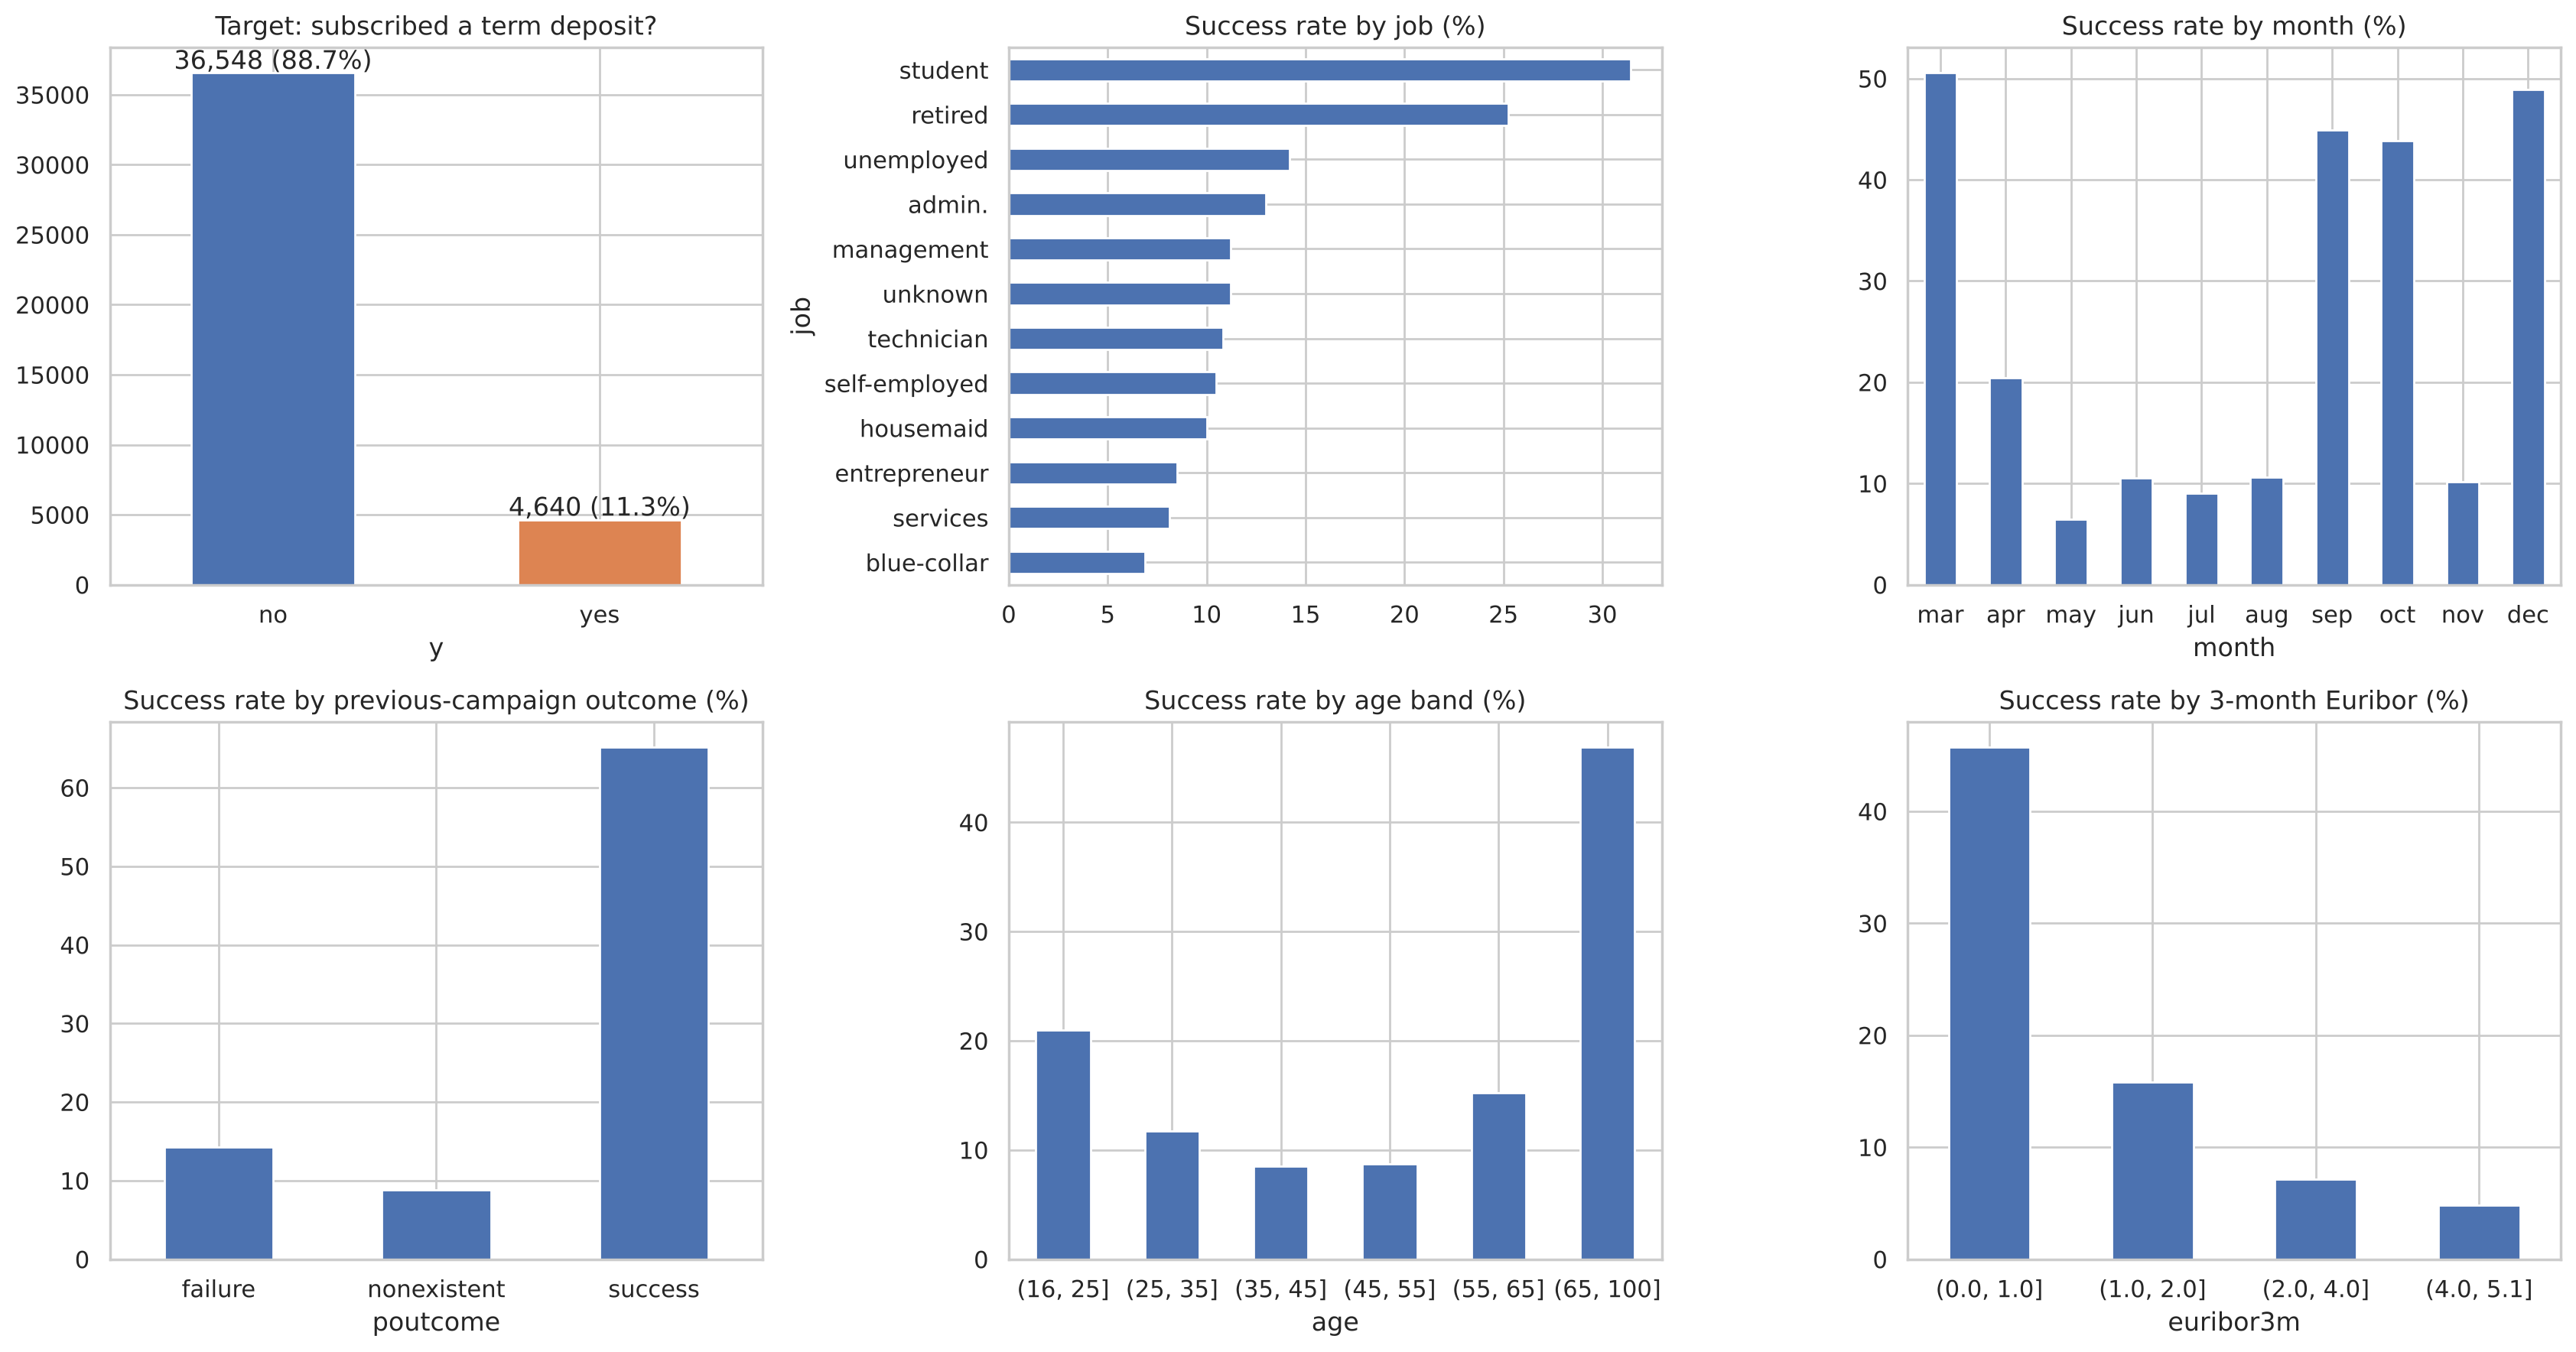

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
bank.y.value_counts().plot.bar(ax=ax[0,0], color=['#4C72B0','#DD8452'], rot=0); ax[0,0].set_title('Target: subscribed a term deposit?')
for i,p in enumerate(bank.y.value_counts()): ax[0,0].text(i, p+300, f'{p:,} ({p/len(bank):.1%})', ha='center')
(bank.groupby('job').target.mean().sort_values()*100).plot.barh(ax=ax[0,1]); ax[0,1].set_title('Success rate by job (%)')
order = ['mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
(bank.groupby('month').target.mean().reindex(order)*100).plot.bar(ax=ax[0,2], rot=0); ax[0,2].set_title('Success rate by month (%)')
(bank.groupby('poutcome').target.mean()*100).plot.bar(ax=ax[1,0], rot=0); ax[1,0].set_title('Success rate by previous-campaign outcome (%)')
(bank.groupby(pd.cut(bank.age,[16,25,35,45,55,65,100])).target.mean()*100).plot.bar(ax=ax[1,1], rot=0); ax[1,1].set_title('Success rate by age band (%)')
(bank.groupby(pd.cut(bank.euribor3m,[0,1,2,4,5.1])).target.mean()*100).plot.bar(ax=ax[1,2], rot=0); ax[1,2].set_title('Success rate by 3-month Euribor (%)')
plt.tight_layout(); plt.show()

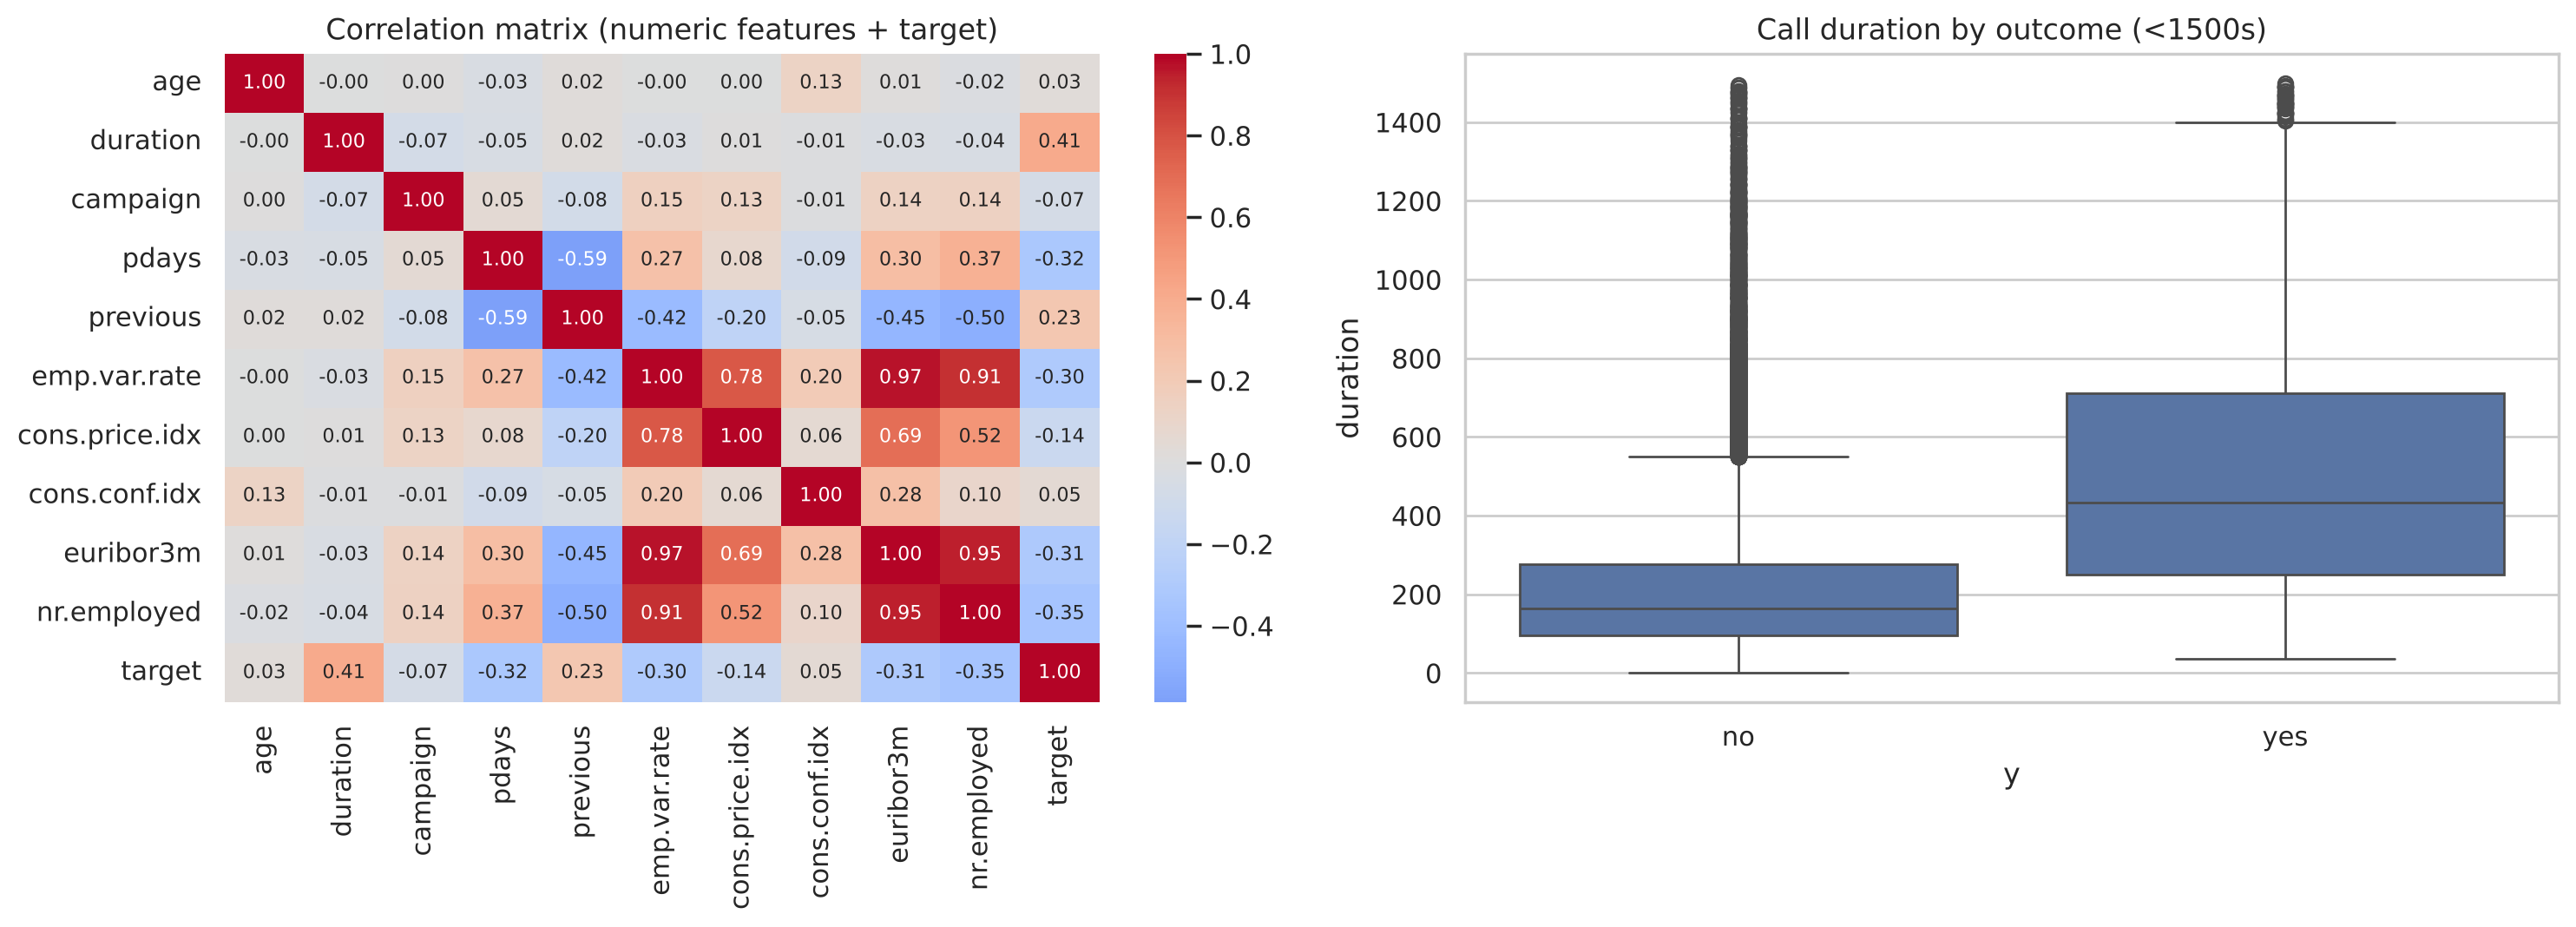

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(bank[num_cols+['target']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[0], annot_kws={'size':8})
ax[0].set_title('Correlation matrix (numeric features + target)')
sns.boxplot(data=bank[bank.duration<1500], x='y', y='duration', ax=ax[1]); ax[1].set_title('Call duration by outcome (<1500s)')
plt.tight_layout(); plt.show()

**Descriptive statistics.** 11.3% of contacts subscribed. Subscribers differ most from non-subscribers on the **macro-economic variables**: median Euribor-3m 1.27% vs 4.86%, employment variation rate −1.8 vs +1.1, number employed 5,099k vs 5,196k. Subscribers also had more previous contacts (mean 0.49 vs 0.13), fewer contacts in the current campaign (2.05 vs 2.63) and a shorter gap since last contact. Age is almost identical (median 37 vs 38).

**Inferential statistics.** All differences below are tested on 41,188 rows, so almost everything is "significant" (p < 0.05); **effect size is what matters**.
* Numeric (Mann–Whitney U, rank-biserial *r*): `duration` r ≈ 0.64 (very large — but leakage), `nr.employed` −0.50, `euribor3m` −0.49, `emp.var.rate` −0.43 (medium-large); `previous` +0.22, `cons.price.idx` −0.22, `pdays` −0.19, `campaign` −0.11 (small); `age` −0.02 (negligible even though p = 0.016).
* Categorical (χ², Cramér's V): `poutcome` V = 0.32 (previous success → **65.1%** conversion vs 8.8% when no prior campaign), `month` 0.27, `job` 0.15 (students 31%, retired also high; blue-collar 6.9%), `contact` 0.15 (cellular **14.7%** vs landline **5.2%**), `default` 0.10. `housing` (p = 0.058) and `loan` (p = 0.58) are **not** statistically associated with subscription; `day_of_week` is significant but tiny (V = 0.025).
* Caution: March/Sep/Oct/Dec show very high rates but are low-volume months, and macro variables are strongly collinear with each other (e.g. `euribor3m` and `nr.employed`) and with *time*, so they partly act as a proxy for which campaign wave a customer was in.

**Implication for modeling:** the seven bank-profile features requested in Problem 5 are the *weakest* predictors in the dataset (Cramér's V ≤ 0.15, several ≈ 0). We should expect a poor first model.

## Problem 5: Engineering Features (bank-information features only)

Per the instructions, the first model uses only the **bank client data**: `age, job, marital, education, default, housing, loan` (features 1–7). Encoding choices:
- `'unknown'` is kept as its own category (it is 0.3–21% of rows; dropping would discard data and `unknown` can itself be informative);
- nominal categoricals → one-hot; `age` → standardised (matters for KNN/SVM/LR);
- target `y` → binary (`yes`=1, `no`=0).

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

bank_feats = ['age','job','marital','education','default','housing','loan']
X1 = bank[bank_feats].copy()
y  = bank['target']

pre1 = ColumnTransformer([
    ('num', StandardScaler(), ['age']),
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['job','marital','education','default','housing','loan'])])
print('Features:', X1.shape, '| target mean:', round(y.mean(), 4))
X1.head()

Features: (41188, 7) | target mean: 0.1127


,age,job,marital,education,default,housing,loan
0,56,housemaid,married,basic.4y,no,no,no
1,57,services,married,high.school,unknown,no,no
2,37,services,married,high.school,no,yes,no
3,40,admin.,married,basic.6y,no,no,no
4,56,services,married,high.school,no,no,yes


## Problem 6: Train/Test Split
A **stratified** 70/30 split keeps the ≈11% positive rate in both sets. Preprocessing lives inside pipelines so scalers/encoders are fit on training data only (no leakage).

In [10]:
from sklearn.model_selection import train_test_split
X1_train, X1_test, y_train, y_test = train_test_split(X1, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
print(X1_train.shape, X1_test.shape)
print('Train positive rate:', round(y_train.mean(),4), '| Test positive rate:', round(y_test.mean(),4))

(28831, 7) (12357, 7)
Train positive rate: 0.1127 | Test positive rate: 0.1126


## Problem 7: A Baseline Model
A model that always predicts the majority class ("no") is the bar to beat.

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
dummy = DummyClassifier(strategy='most_frequent').fit(X1_train, y_train)
base_acc = accuracy_score(y_test, dummy.predict(X1_test))
print(f'Baseline (always predict "no") test accuracy: {base_acc:.4f}')

Baseline (always predict "no") test accuracy: 0.8874


**Baseline = 88.74% test accuracy** (always predict "no", the majority class). Any useful classifier must beat this — and, because accuracy rewards ignoring subscribers, must also be judged on recall, AUC and lift.

## Problem 8: A Simple Model — Logistic Regression

In [12]:
lr_simple = Pipeline([('prep', pre1), ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]) if 'LogisticRegression' in globals() else None
from sklearn.linear_model import LogisticRegression
lr_simple = Pipeline([('prep', pre1), ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
lr_simple.fit(X1_train, y_train)
print('Fitted. Intercept:', lr_simple.named_steps['clf'].intercept_.round(3))

Fitted. Intercept: [-0.85]


## Problem 9: Score the Model

In [13]:
from sklearn.metrics import recall_score, roc_auc_score
pred = lr_simple.predict(X1_test)
print(f'Train accuracy: {lr_simple.score(X1_train, y_train):.4f}')
print(f'Test accuracy : {lr_simple.score(X1_test,  y_test):.4f}   (baseline {base_acc:.4f})')
print(f'Test recall (subscribers found): {recall_score(y_test, pred):.4f}')
print(f'Test ROC-AUC: {roc_auc_score(y_test, lr_simple.predict_proba(X1_test)[:,1]):.4f}')

Train accuracy: 0.8873
Test accuracy : 0.8874   (baseline 0.8874)
Test recall (subscribers found): 0.0000


Test ROC-AUC: 0.6538


**The logistic regression's test accuracy is 88.74% — exactly the baseline.** The model has learned nothing useful: it predicts "no" for every customer (recall 0.0%), so it would find zero subscribers. Its ROC-AUC of 0.654 shows the features do carry a *little* ranking signal, but not enough to push any probability above 0.5. This is the classic imbalanced-class trap and motivates the metric change in Problem 11.

## Problem 10: Model Comparisons (default settings, bank features only)

In [14]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'KNN':                 KNeighborsClassifier(),
    'Decision Tree':       DecisionTreeClassifier(random_state=RANDOM_STATE),
    'SVM':                 SVC(random_state=RANDOM_STATE),
}
rows = []
for name, clf in models.items():
    pipe = Pipeline([('prep', pre1), ('clf', clf)])
    t0 = time.perf_counter(); pipe.fit(X1_train, y_train); fit_t = time.perf_counter() - t0
    rows.append([name, fit_t, pipe.score(X1_train, y_train), pipe.score(X1_test, y_test)])
res1 = pd.DataFrame(rows, columns=['Model','Train Time (s)','Train Accuracy','Test Accuracy']).set_index('Model')
res1.loc['Baseline (majority)'] = [0.0, dummy.score(X1_train, y_train), base_acc]
res1.round(4)

,Train Time (s),Train Accuracy,Test Accuracy
Model,,,
Logistic Regression,0.0669,0.8873,0.8874
KNN,0.0325,0.8918,0.8769
Decision Tree,0.5055,0.9188,0.8642
SVM,41.8123,0.8882,0.8868
Baseline (majority),0.0000,0.8873,0.8874


| Observation | Detail |
|---|---|
| **Accuracy gives no separation** | All four models sit at 86–89% test accuracy; none beats the 88.74% baseline. LR (88.74%) and SVM (88.68%) are effectively the baseline; KNN (87.7%) and Decision Tree (86.4%) are *worse*. |
| **Overfitting** | The unconstrained Decision Tree has the largest train–test gap (91.9% vs 86.4%); KNN shows a smaller one (89.2% vs 87.7%). LR and SVM show none. |
| **Training time** | LR ≈ 0.07 s, KNN ≈ 0.03 s (lazy learner: cost is deferred to prediction), Decision Tree ≈ 0.5 s, **SVM ≈ 42 s** — roughly 600× slower than LR for no accuracy gain. |

**Conclusion:** with bank-profile features only, no model is meaningfully better than guessing "no". The bottleneck is information in the features, not the algorithm — so the next step is better features and better metrics, not just tuning.

## Problem 11: Improving the Model

Two levers from the assignment: **(a) richer features / better metric** and **(b) hyperparameter tuning with grid search**.

### 11a. Why accuracy is the wrong yardstick here
With an 88.7 / 11.3 class split, a model can score ~89% accuracy while finding *zero* subscribers. The business needs to **rank customers so that the call centre contacts the likeliest buyers first**, so we switch to **ROC-AUC** (ranking quality), **PR-AUC / average precision** (robust to imbalance), and **recall / precision / F1** for the positive class.

### 11b. Feature set expansion — and the `duration` leakage trap
The dataset documentation warns that `duration` (call length) is only known *after* the call, so it must be excluded from any realistic model. We prove why by benchmarking it once, then drop it for everything else.

In [15]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)

df = bank.copy()
df['previously_contacted'] = (df.pdays != 999).astype(int)
df['pdays'] = df.pdays.replace(999, 0)           # 999 = 'never contacted' -> flag + 0

num_all = ['age','campaign','pdays','previous','previously_contacted','emp.var.rate','cons.price.idx','cons.conf.idx','euribor3m','nr.employed']
cat_all = ['job','marital','education','default','housing','loan','contact','month','day_of_week','poutcome']
def make_pre(nums, cats):
    return ColumnTransformer([('num', StandardScaler(), nums), ('cat', OneHotEncoder(handle_unknown='ignore'), cats)])

idx_train, idx_test = X1_train.index, X1_test.index     # SAME rows as before -> comparable
XA_train, XA_test = df.loc[idx_train, num_all+cat_all], df.loc[idx_test, num_all+cat_all]

def evaluate(pipe, Xtr, Xte, score_fn=None):
    s = pipe.predict_proba(Xte)[:,1] if hasattr(pipe, 'predict_proba') else pipe.decision_function(Xte)
    p = pipe.predict(Xte)
    return dict(Accuracy=accuracy_score(y_test,p), Precision=precision_score(y_test,p,zero_division=0),
                Recall=recall_score(y_test,p), F1=f1_score(y_test,p), ROC_AUC=roc_auc_score(y_test,s),
                PR_AUC=average_precision_score(y_test,s)), s

# leakage demonstration (logistic regression only)
lr_leak = Pipeline([('p', make_pre(num_all+['duration'], cat_all)), ('c', LogisticRegression(max_iter=2000))]).fit(
    df.loc[idx_train, num_all+['duration']+cat_all], y_train)
lr_ok = Pipeline([('p', make_pre(num_all, cat_all)), ('c', LogisticRegression(max_iter=2000))]).fit(XA_train, y_train)
lr_bank = lr_simple
cmp = pd.DataFrame({
  'Bank features only':               evaluate(lr_bank, X1_train, X1_test)[0],
  'All pre-call features (no duration)': evaluate(lr_ok, XA_train, XA_test)[0],
  'WITH duration (leaky benchmark)':  evaluate(lr_leak, None, df.loc[idx_test, num_all+['duration']+cat_all])[0]}).T
cmp.round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Bank features only,0.8874,0.0000,0.0000,0.0000,0.6538,0.2049
All pre-call features (no duration),0.9010,0.6916,0.2191,0.3328,0.8034,0.4683
WITH duration (leaky benchmark),0.9122,0.6746,0.4260,0.5222,0.9383,0.6064


**Reading the table (Logistic Regression, same train/test rows):**
* Bank features only: ROC-AUC 0.654, PR-AUC 0.205, recall 0.
* Adding all other **pre-call** features: ROC-AUC **0.803**, PR-AUC 0.468, precision 0.69. A very large improvement from legitimately available information.
* Adding `duration`: ROC-AUC 0.938 — an impressive-looking jump, but it is **not usable**: call length is only known once the call is over (and a long call is largely a *consequence* of customer interest). The original paper's headline AUC of 0.938 for its SVM includes this kind of variable, which is why they note it cannot be used directly for contact selection. We therefore exclude `duration` from all models that follow.

### 11c. All four models with the expanded (pre-call) feature set — default settings

In [16]:
rows, fitted_default = [], {}
for name, clf in models.items():
    pipe = Pipeline([('prep', make_pre(num_all, cat_all)), ('clf', clf)])
    t0 = time.perf_counter(); pipe.fit(XA_train, y_train); ft = time.perf_counter() - t0
    m, _ = evaluate(pipe, XA_train, XA_test); m['Train Time (s)'] = ft; m['Train Acc'] = pipe.score(XA_train, y_train)
    rows.append(pd.Series(m, name=name)); fitted_default[name] = pipe
res2 = pd.DataFrame(rows)[['Train Time (s)','Train Acc','Accuracy','Precision','Recall','F1','ROC_AUC','PR_AUC']]
res2.round(4)

,Train Time (s),Train Acc,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Logistic Regression,0.2027,0.8999,0.9010,0.6916,0.2191,0.3328,0.8034,0.4683
KNN,0.0603,0.9109,0.8967,0.5809,0.2967,0.3928,0.7423,0.3561
Decision Tree,0.2474,0.9962,0.8377,0.3029,0.3384,0.3196,0.6206,0.1781
SVM,50.3694,0.9059,0.9026,0.6895,0.2457,0.3623,0.7033,0.4200


**Default settings on the richer feature set** (ROC-AUC / PR-AUC are the headline metrics):
* **Logistic Regression** is the best out-of-the-box ranker (ROC-AUC 0.803, PR-AUC 0.468, precision 0.69) but, at the 0.5 threshold, still finds only 22% of subscribers.
* **SVM** (RBF) is close on accuracy (90.3%) but worse at ranking (AUC 0.703), and takes ≈ 50 s to train.
* **KNN** gets the best F1 among defaults (0.39) but ranks poorly (AUC 0.742).
* **Decision Tree** with no depth limit memorises the training data (train accuracy 99.6% vs test 83.8%, AUC 0.621) — a textbook overfit that tuning must fix.

### 11d. Hyperparameter tuning (GridSearchCV, 3-fold stratified CV on the training set, optimising ROC-AUC)
SVM is expensive (O(n²–n³)), so its grid is searched on a 10,000-row stratified subsample of the *training* data and the winning configuration is then refit on the full training set. The test set is never touched during tuning.

In [17]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
cv = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
grids = {
 'Logistic Regression': (LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        {'clf__C':[0.01,0.1,1,10], 'clf__class_weight':[None,'balanced']}),
 'KNN': (KNeighborsClassifier(),
        {'clf__n_neighbors':[5,15,31,51,101], 'clf__weights':['uniform','distance']}),
 'Decision Tree': (DecisionTreeClassifier(random_state=RANDOM_STATE),
        {'clf__max_depth':[3,5,7,10], 'clf__min_samples_leaf':[20,50,100], 'clf__class_weight':[None,'balanced']}),
 'SVM': (SVC(random_state=RANDOM_STATE),
        {'clf__C':[0.1,1,10], 'clf__gamma':['scale',0.01], 'clf__class_weight':[None,'balanced']}),
}
tuned, search_rows = {}, []
for name,(clf,grid) in grids.items():
    pipe = Pipeline([('prep', make_pre(num_all, cat_all)), ('clf', clf)])
    gs = GridSearchCV(pipe, grid, scoring='roc_auc', cv=cv, n_jobs=-1)
    t0 = time.perf_counter()
    if name == 'SVM':
        sub = XA_train.sample(10000, random_state=RANDOM_STATE)
        gs.fit(sub, y_train.loc[sub.index])
        best = gs.best_estimator_.set_params(); best = Pipeline([('prep', make_pre(num_all, cat_all)),
                ('clf', SVC(random_state=RANDOM_STATE, **{k[5:]:v for k,v in gs.best_params_.items()}))])
        t1 = time.perf_counter(); best.fit(XA_train, y_train); fit_t = time.perf_counter() - t1
    else:
        gs.fit(XA_train, y_train); best = gs.best_estimator_
        t1 = time.perf_counter(); best.fit(XA_train, y_train); fit_t = time.perf_counter() - t1
    tuned[name] = best
    search_rows.append([name, {k[5:]:v for k,v in gs.best_params_.items()}, round(gs.best_score_,4), round(time.perf_counter()-t0,1)])
pd.DataFrame(search_rows, columns=['Model','Best hyperparameters','CV ROC-AUC','Search time (s)']).set_index('Model')

,Best hyperparameters,CV ROC-AUC,Search time (s)
Model,,,
Logistic Regression,"{'C': 0.1, 'class_weight': 'balanced'}",0.7859,4.6
KNN,"{'n_neighbors': 101, 'weights': 'uniform'}",0.7807,30.5
Decision Tree,"{'class_weight': None, 'max_depth': 7, 'min_sa...",0.7852,8.8
SVM,"{'C': 1, 'class_weight': 'balanced', 'gamma': ...",0.7667,135.2


In [18]:
rows, scores = [], {}
for name, pipe in tuned.items():
    m, s = evaluate(pipe, XA_train, XA_test); scores[name] = s
    rows.append(pd.Series(m, name=name))
res3 = pd.DataFrame(rows)
print('TUNED models — test-set performance (default 0.5 / 0 decision threshold):')
display(res3.round(4))
print('Compared with DEFAULT models on the same features:')
display(res2[['Accuracy','Precision','Recall','F1','ROC_AUC','PR_AUC']].round(4))

TUNED models — test-set performance (default 0.5 / 0 decision threshold):


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Logistic Regression,0.8309,0.3605,0.6480,0.4633,0.8028,0.4617
KNN,0.9008,0.6853,0.2205,0.3337,0.7939,0.4526
Decision Tree,0.8980,0.6138,0.2557,0.3611,0.8039,0.4422
SVM,0.8356,0.3674,0.6372,0.4661,0.7876,0.4020


Compared with DEFAULT models on the same features:


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Logistic Regression,0.9010,0.6916,0.2191,0.3328,0.8034,0.4683
KNN,0.8967,0.5809,0.2967,0.3928,0.7423,0.3561
Decision Tree,0.8377,0.3029,0.3384,0.3196,0.6206,0.1781
SVM,0.9026,0.6895,0.2457,0.3623,0.7033,0.4200


**Tuning results.**
* **Decision Tree benefits most**: limiting depth (`max_depth = 7`) and leaf size raises test ROC-AUC from 0.621 → **0.804** and PR-AUC from 0.178 → 0.442, removing the overfit.
* **KNN** improves from AUC 0.742 → 0.794 by using many more neighbours (k = 101) — smoother, less noisy local averages.
* **Logistic Regression** keeps AUC ≈ 0.803 but, with `class_weight='balanced'`, **recall jumps from 22% → 65%** (precision falls 69% → 36%, accuracy 90% → 83%). Same ranking quality, different operating point: it deliberately trades accuracy for finding subscribers.
* **SVM** (balanced, tuned on a subsample) reaches F1 0.466 and recall 64% but remains the weakest ranker (AUC 0.788) and by far the most expensive (~135 s just for the search).
* **Take-away:** after tuning, LR, Decision Tree and KNN are statistically very close on ROC-AUC (0.794–0.804 — a 0.01 gap on a 12,357-row test set is within noise), so the choice should rest on **interpretability, speed and operating-point control**, which favour Logistic Regression.

### 11e. Aligning the model with the business goal: ranking, gains and lift
Rather than a hard yes/no at 0.5, the bank can **call the top-scoring X% of customers**. The cumulative gains table (the Lift metric the paper recommends for marketing) shows what share of all subscribers is captured by contacting only the top deciles.

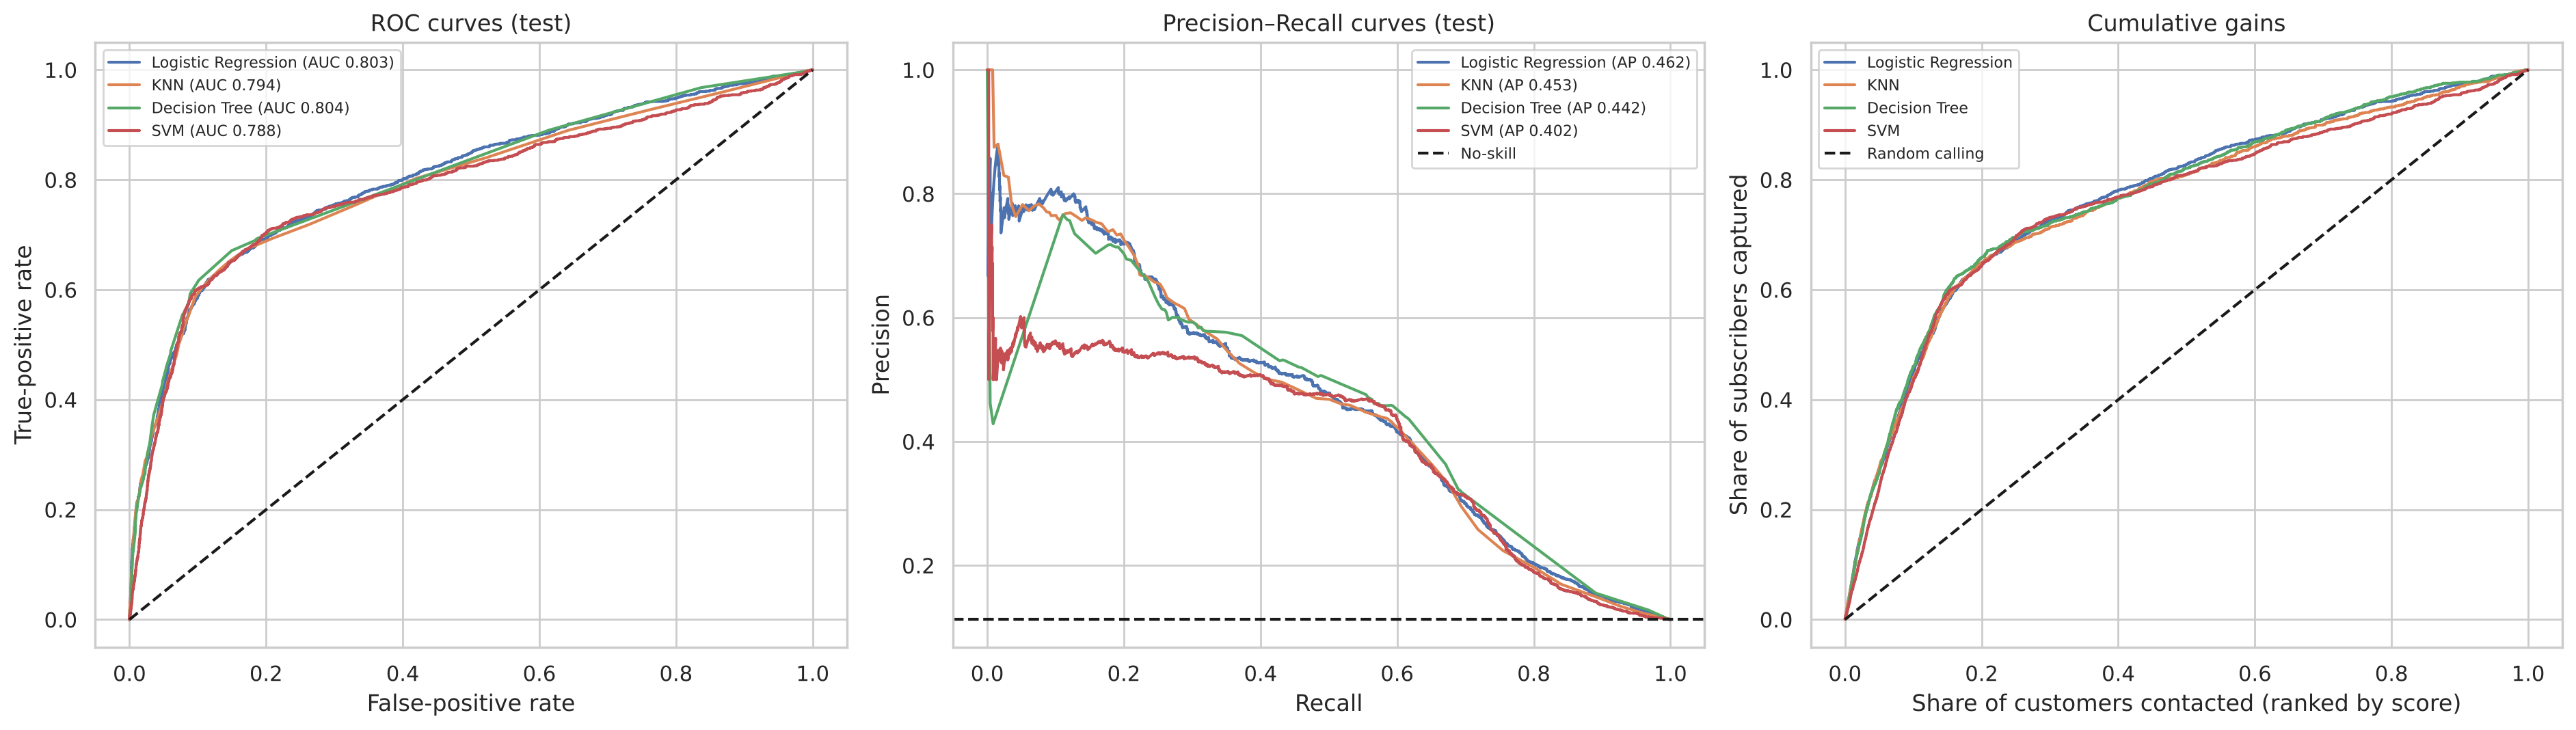

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(y_test, s); ax[0].plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(y_test,s):.3f})')
    pr, rc, _ = precision_recall_curve(y_test, s); ax[1].plot(rc, pr, label=f'{name} (AP {average_precision_score(y_test,s):.3f})')
    order_ = np.argsort(-s); cum = np.cumsum(y_test.values[order_]) / y_test.sum()
    ax[2].plot(np.arange(1,len(cum)+1)/len(cum), cum, label=name)
ax[0].plot([0,1],[0,1],'k--'); ax[0].set(title='ROC curves (test)', xlabel='False-positive rate', ylabel='True-positive rate')
ax[1].axhline(y_test.mean(), color='k', ls='--', label='No-skill'); ax[1].set(title='Precision–Recall curves (test)', xlabel='Recall', ylabel='Precision')
ax[2].plot([0,1],[0,1],'k--', label='Random calling'); ax[2].set(title='Cumulative gains', xlabel='Share of customers contacted (ranked by score)', ylabel='Share of subscribers captured')
for a in ax: a.legend(loc='best', fontsize=8)
plt.tight_layout(); plt.show()

In [20]:
best_name = res3.ROC_AUC.idxmax(); print('Best model by test ROC-AUC:', best_name)
s = scores[best_name]; yt = y_test.values; o = np.argsort(-s)
rows = []
for frac in [0.05,0.10,0.20,0.30,0.50]:
    k = int(len(s)*frac); hit = yt[o][:k].sum()
    rows.append([f'Top {frac:.0%}', k, hit, hit/yt.sum(), (hit/k), (hit/k)/yt.mean()])
gain = pd.DataFrame(rows, columns=['Contact','Customers called','Subscribers found','% of all subscribers captured','Hit-rate in group','Lift vs random']).set_index('Contact')
gain.style.format({'% of all subscribers captured':'{:.1%}','Hit-rate in group':'{:.1%}','Lift vs random':'{:.2f}x'})

Best model by test ROC-AUC: Decision Tree


,Customers called,Subscribers found,% of all subscribers captured,Hit-rate in group,Lift vs random
Contact,,,,,
Top 5%,617,369,26.5%,59.8%,5.31x
Top 10%,1235,641,46.0%,51.9%,4.61x
Top 20%,2471,917,65.9%,37.1%,3.29x
Top 30%,3707,1004,72.1%,27.1%,2.40x
Top 50%,6178,1143,82.1%,18.5%,1.64x


**Cumulative gains (best model by test AUC, the tuned Decision Tree):** calling only the **top 10%** of ranked customers captures **46%** of all subscribers (hit-rate 52% vs 11.3% average, 4.6× lift); the **top 20%** captures **66%** (3.3× lift); the **top 30%** captures 72%. Returns diminish quickly after that — the last 50% of the list contains only ~18% of subscribers. A tuned LR gives a very similar curve (see the gains plot), so this value does not depend on picking one specific algorithm.

(Note: the tree's AUC 0.8039 vs LR's 0.8028 is a statistical tie; we recommend LR for the reasons above.)

### 11f. Confusion matrix and threshold choice for the best model
The default 0.5 threshold is too conservative for an 11% positive class. We choose the threshold that maximises F1 on the training data via cross-validated scores (not the test set), then report the test result.

Chosen threshold (max CV-F1 on train): 0.180
Test  Precision 0.458 | Recall 0.593 | F1 0.517 | Accuracy 0.875


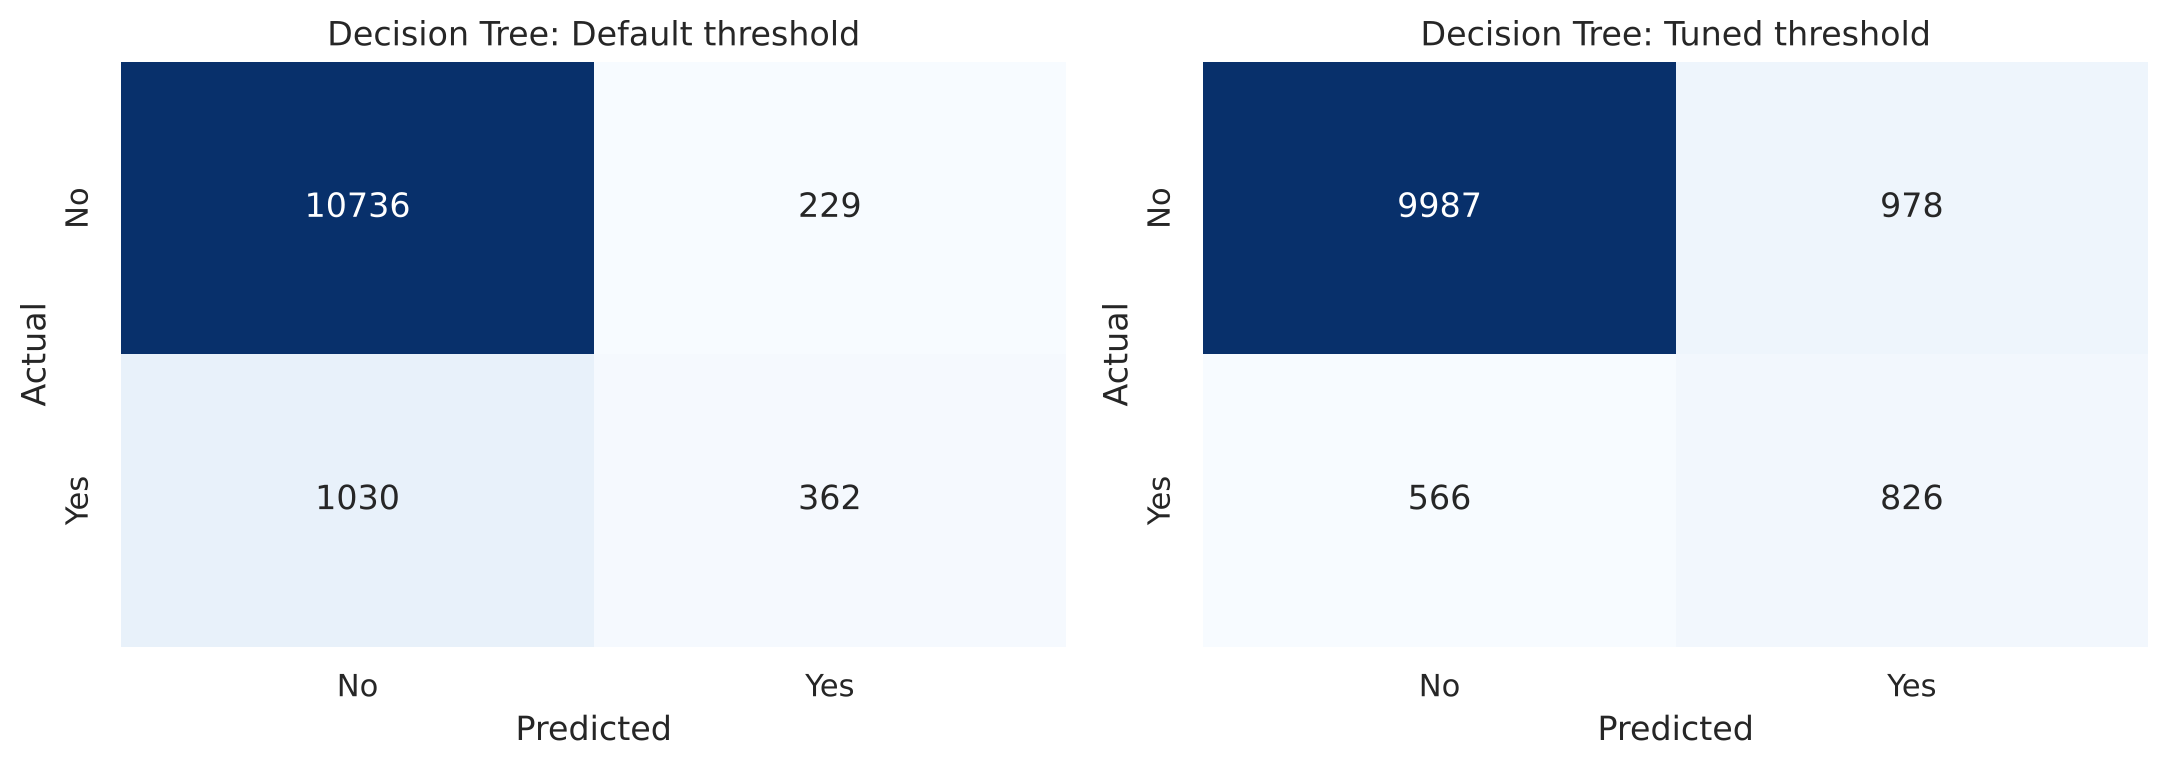

In [21]:
from sklearn.model_selection import cross_val_predict
best_pipe = tuned[best_name]
cv_scores = cross_val_predict(best_pipe, XA_train, y_train, cv=cv, method='predict_proba' if hasattr(best_pipe,'predict_proba') else 'decision_function')
cv_scores = cv_scores[:,1] if cv_scores.ndim==2 else cv_scores
p_, r_, th_ = precision_recall_curve(y_train, cv_scores)
f1s = 2*p_*r_/(p_+r_+1e-12); thr = th_[np.argmax(f1s[:-1])]
pred_thr = (scores[best_name] >= thr).astype(int)
print(f'Chosen threshold (max CV-F1 on train): {thr:.3f}')
print(f'Test  Precision {precision_score(y_test,pred_thr):.3f} | Recall {recall_score(y_test,pred_thr):.3f} | F1 {f1_score(y_test,pred_thr):.3f} | Accuracy {accuracy_score(y_test,pred_thr):.3f}')
fig, ax = plt.subplots(1,2, figsize=(11,4))
for a, pr_, ttl in zip(ax, [(scores[best_name] >= (0.5 if hasattr(best_pipe,'predict_proba') else 0)).astype(int), pred_thr], ['Default threshold','Tuned threshold']):
    sns.heatmap(confusion_matrix(y_test, pr_), annot=True, fmt='d', cmap='Blues', cbar=False, ax=a,
                xticklabels=['No','Yes'], yticklabels=['No','Yes']); a.set(title=f'{best_name}: {ttl}', xlabel='Predicted', ylabel='Actual')
plt.tight_layout(); plt.show()

### 11g. What drives subscription? (interpretation via tuned Logistic Regression)

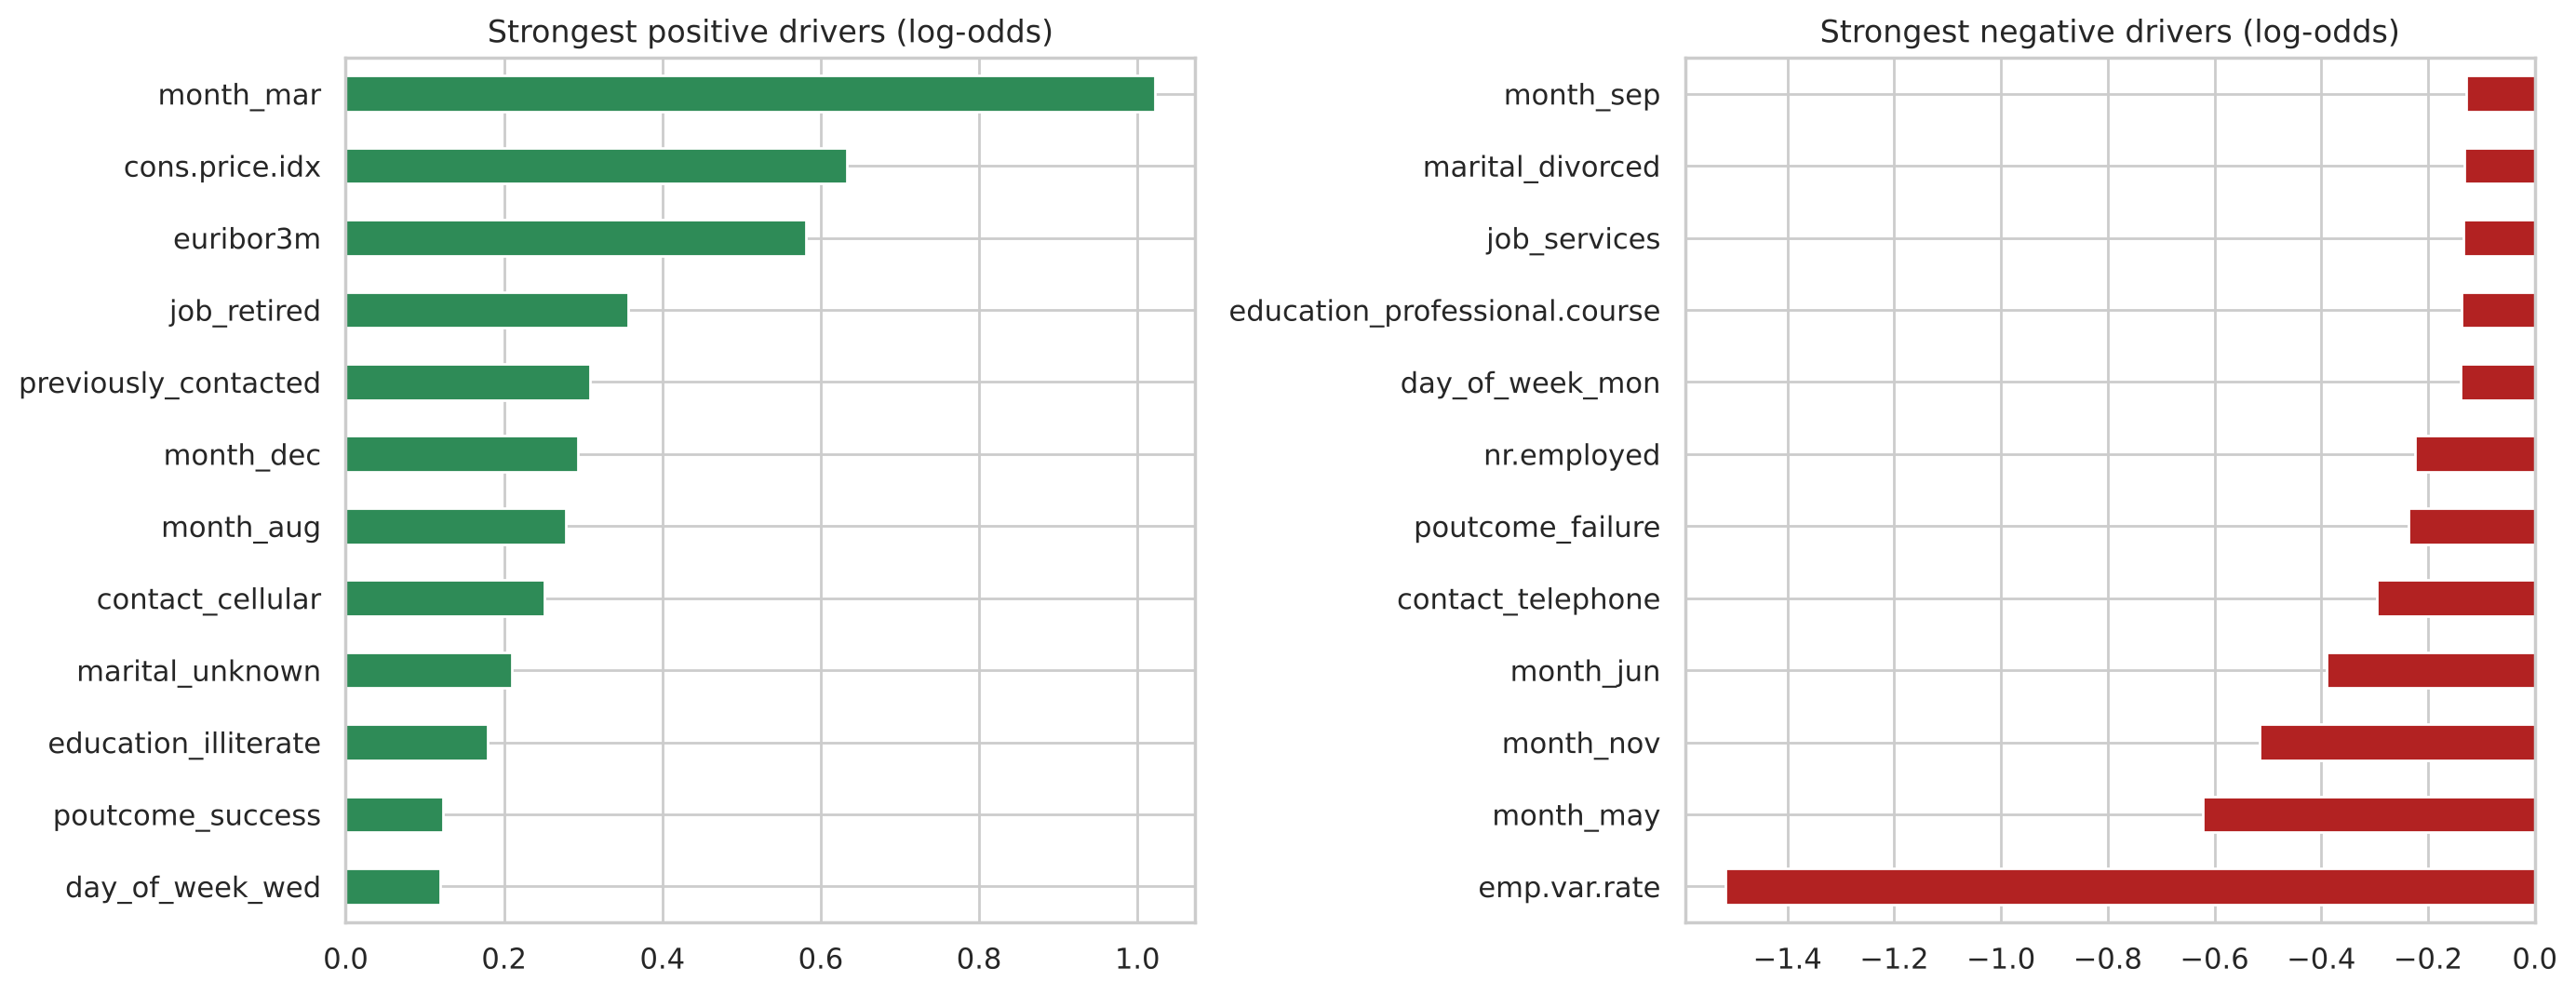

Decision-tree top importances:


nr.employed             0.606
previously_contacted    0.107
euribor3m               0.067
cons.conf.idx           0.057
age                     0.021
month_oct               0.020
day_of_week_mon         0.017
campaign                0.017
dtype: float64

In [22]:
lr_best = tuned['Logistic Regression']
names = lr_best.named_steps['prep'].get_feature_names_out()
coef = pd.Series(lr_best.named_steps['clf'].coef_[0], index=[n.split('__')[1] for n in names]).sort_values()
fig, ax = plt.subplots(1,2, figsize=(14,5.5))
coef.tail(12).plot.barh(ax=ax[0], color='seagreen'); ax[0].set_title('Strongest positive drivers (log-odds)')
coef.head(12).plot.barh(ax=ax[1], color='firebrick'); ax[1].set_title('Strongest negative drivers (log-odds)')
plt.tight_layout(); plt.show()

tree = tuned['Decision Tree']
imp = pd.Series(tree.named_steps['clf'].feature_importances_, index=[n.split('__')[1] for n in tree.named_steps['prep'].get_feature_names_out()]).sort_values(ascending=False)
print('Decision-tree top importances:'); display(imp.head(8).round(3))

**What drives subscription (consistent across LR coefficients and tree importances):**
* **Macro-economic climate** is the dominant factor: the tree puts 61% of its importance on `nr.employed` and a further 7% on `euribor3m`; in LR, `emp.var.rate` has the largest negative coefficient. Customers respond when interest rates are low and employment conditions are weak/shifting (deposits are attractive and people are cautious).
* **Prior relationship**: having been contacted before (`previously_contacted`, 10.7% tree importance; positive LR coefficient) — and especially a previous *success* (65% conversion).
* **Channel and timing**: **cellular** contacts convert ~2.8× more than landline; **March, December, (also Sept/Oct)** are strongest, **May** (the busiest month) and **June/November** the weakest.
* **Segments**: retirees (and students) respond better than average; blue-collar workers worse.
* Demographic/credit variables (`housing`, `loan`, `marital`, `age`) contribute little.

## Findings, Actionable Insights, Next Steps & Recommendations

### Findings
1. **The target is rare (11.3%) so accuracy is a trap.** A majority-class baseline gets 88.74% accuracy; bank-profile-only models cannot beat it (LR: recall 0%).
2. **Information content, not algorithm choice, determines performance.** Moving from client-profile features to pre-call contact/history/macro features raises ROC-AUC from 0.65 to ~0.80. Tuning then matters mainly for the Decision Tree (0.62 → 0.80) and KNN (0.74 → 0.79).
3. **After tuning, LR, DT and KNN are tied (AUC 0.79–0.80); SVM is not better and is the slowest** (≈ 40–50 s to fit vs < 1 s for the others, ~135 s to tune).
4. **Threshold/metric choice sets the business trade-off.** At the F1-optimised threshold (0.18) the tuned tree gives precision 0.46, recall 0.59, F1 0.52 on the test set — i.e. roughly 1 in 2 calls succeeds (vs 1 in 9 with random calling) while reaching ~60% of buyers.
5. **`duration` is leakage:** it lifts AUC to 0.94 but cannot be known before dialling.

### Actionable insights
* **Rank, don't classify.** Score the customer list and call from the top: the top 20% of the list yields ~66% of subscriptions (3.3× lift); the top 10% yields a ~52% hit-rate.
* **Prioritise warm leads:** customers with a previous successful campaign convert at 65% — contact them first, every campaign.
* **Use cellular numbers** where available (14.7% vs 5.2% on landlines).
* **Time campaigns to the economic cycle and calendar:** launch deposit drives when rates are low/falling and avoid over-concentrating calls in May, the highest-volume but lowest-converting month.
* **Reduce repeated dialling:** more contacts within a campaign correlates with *lower* success (2.05 vs 2.63 mean contacts) — cap attempts per customer.
* **Segment messaging:** retirees and students are over-indexed; blue-collar workers under-indexed.

### Next steps & recommendations
1. **Deploy tuned Logistic Regression** (class-weight balanced) as the scoring model; use the tree as a transparent rule-set companion. Do not deploy the SVM (cost without benefit).
2. **Choose the call-depth/threshold with finance,** using the gains table: compare cost per call to expected deposit value per subscriber to pick the optimal cut-off (e.g. top 20–30%).
3. **Validate over time.** The file is ordered by date and macro variables partly proxy for campaign period (2008–10 crisis), so a random split is optimistic. Re-test with a **chronological split** (train on early months, test on late months) and monitor drift in production.
4. **Add richer data:** the original paper had 59 attributes (balance, product holdings, online-banking visits, agent). The UCI extract dropped many for privacy; recovering customer-level financial/behavioural features is the highest-value upgrade.
5. **Improve modeling:** try gradient-boosted trees and calibrated probabilities; test cost-sensitive learning; use stratified repeated CV for tighter confidence intervals on AUC.
6. **Fairness & compliance review:** check that targeting by age/job/marital status does not create discriminatory outcomes and respects contact-consent rules (the paper flags privacy irritation as a risk of direct marketing).
7. **Run an A/B pilot:** model-ranked vs. current call lists in one campaign to measure real-world lift before full roll-out.

##### Questions

**Q1. How many campaigns?** 17 (May 2008 – Nov 2010).  
**Q2. What is the baseline to beat?** 88.74% accuracy (predict "no") — and, more importantly, recall/AUC/lift above what random calling achieves.  
**Q3. Which model is best?** On ranking quality the tuned LR (0.803), Decision Tree (0.804) and KNN (0.794) are tied; SVM is slightly lower (0.788) and far slower. Choose **tuned Logistic Regression** for interpretability, speed and threshold control.  
**Q4. Why not just report accuracy?** Because 89% of customers say "no"; accuracy rewards models that ignore subscribers.  
**Q5. Why was `duration` removed?** It is only known after the call (leakage); including it inflates AUC to 0.94 but gives a model that cannot be used to choose whom to call.  
**Q6. Main limitations?** Random (not chronological) split; macro variables proxy for time; one country/bank; `unknown` values treated as a category; hyperparameter search for SVM done on a 10k subsample; no probability calibration or cost model yet.

*Citation: Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. Decision Support Systems.*